In [92]:
import pandas as pd
import numpy as np
import networkx as nx
import igraph as ig
import matplotlib.pyplot as plt

import multiprocessing
import itertools
import os
import json
import pickle
import statistics

from collections import Counter

import tailestim
from tailestim import HillEstimator

Compressed and formatted data dump is available here (2.4GB): [https://kaikki.org/dictionary/raw-wiktextract-data.jsonl.gz](https://kaikki.org/dictionary/raw-wiktextract-data.jsonl.gz)

**This dump decompresses to 24GB and requires ~50GB of disk space once split into separate files for creating the network. With the saved pickles, this directory takes about ~62GB of disk space on my machine.**

To split into separate files so you don't have to read the entire dump into memory at once, this notebook expects to read from a folder called ``data/split_{size}/`` with files named ``x####.jsonl``.
The size is arbitrary, but I just took the first 100k and 1m lines of the dump for testing before I ran it on the whole dump.
I found that splitting the file into ``.jsonl``s of 1000 lines each worked best for my machine.
You can do this with:
```
split -a 5 --additional-suffix=.jsonl -d -l 1000 raw-wiktextract-data.jsonl ./split_{size}/x
```
I recommend first running this with only 100k lines or so of the dump to make sure it works on your machine before running it on the entire dataset.
There are just over 10m lines in the full dump and it takes me about **20-30 minutes** to format it with 2x Xeon E5-2690v2 using 35 threads.
Hopefully your machine is faster.

This notebook expects the following folder structure (though you can name your split sizes however, just make sure it's reflected in the ``name`` variable in the cell below):

```
├── data
│   ├── split_100k
│   ├── split_1m
│   └── split_all 
├── data_out
│   ├── df_pickles
│   │   ├── split_100k
│   │   ├── split_1m
│   │   └── split_all
│   ├── g_pickles
│   └── graphml
├── figures
└── notebooks

```


In [2]:
data_path = "../data_out"

df_pickles = os.path.join(data_path, "df_pickles")
g_pickles = os.path.join(data_path, "g_pickles")
graphml = os.path.join(data_path, "graphml")


# test networks

name = "all"
# name = "1m"
# name = "100k"


## Format data from ``raw-wiktextract-data.jsonl``

**This step may take a very long time to run.**

In [3]:

def get_word_tree(word, parent=None, depth=0, max_depth=0, langs=[]):


    word_df = pd.DataFrame()
    
    if depth > max_depth:
        return word_df

    # if it's not a word, it's probably a language/dialect with children,
    # so skip ahead to getting next level
    if "word" in word.keys():


        # don't count bigrams/phrases or short words
        # TODO -- add regex here to filter acronyms and abbreviations
        if " " in word["word"] or word["word"] == "": # or len(word["word"]) < 2:
            return word_df


        # skip languages we don't want
        if langs != [] and word["lang_code"] not in langs:
            return word_df


        # check for alternate forms
        form_of = word.get("senses", [{}])[0].get("form_of", [{}])[0].get("word", None)
        alt_of = word.get("senses", [{}])[0].get("alt_of", [{}])[0].get("word", None)


        # get part of speech if it exists -- only head pages have pos, any descendants or parents
        # listed don't, and words are not guarenteed to have the same pos between languages
        pos = word.get("pos", None)


        # word gets set to head_template in word_df, if it exists, for proper ancestry
        # head_template contains special characters; ex: ang "twa" vs. ang "twā"
        head_template = word.get("head_templates", [{}])[0].get("expansion", None)


        # head template sometimes contains info on word gender, plural forms, etc.
        if head_template is not None:

            # anything after parens is never part of the word; remove trailing spaces
            head_template = head_template.split("(")[0].strip()

            # if there's anything else, usually it's a noun gender
            if len(head_template.split()) > 1:
                # romanian is weird and has an "a " prefex for their infinitive verbs
                if word["lang_code"] == "ro" and head_template.split()[0] == "a":
                    head_template = head_template.split()[1]
                elif len(head_template.split()[1]) == 1:
                    head_template = head_template.split()[0]


            if head_template == "":
                head_template = None


        # get inflections, if any, since many of them have their own pages
        if "forms" in word.keys():
            inflections = []
            alternatives = []
           
            for form in word["forms"]:
                # if it's only 1 item then it's table formatting data; also ignore short words
                if "tags" in form:
                    if len(form["tags"]) > 1 and len(form["form"]) > 1:
                        inflections.append(form["form"])
                    elif "alternative" in form["tags"]:
                        alternatives.append(form["form"])
                
            # remove duplicates and make hashable for dataframe
            inflections = frozenset(inflections) if len(inflections) > 0 else None
            alternatives = frozenset(alternatives) if len(alternatives) > 0 else None
        else:
            inflections = None
            alternatives = None



        # get inheritence
        inh_from = None
        bor_from = None
        affix = None
        if "etymology_templates" in word.keys():
            for template in word["etymology_templates"]:
                # if template["name"] == "unc":   # uncertain origin; don't inlcude
                #     continue
                if template["name"] in ["inh", "inh+"]:
                    inh_word = template["args"]["3"] if "3" in template["args"] else None
                    inh_lang = template["args"]["2"] if "2" in template["args"] else None

                    if inh_word == None or inh_lang == None:
                        continue

                    if inh_word == "-":
                        try:
                            inh_word = head_template if head_template is not None else word["word"]
                        except Exception as e:
                            print(f"{inh_word=}, {word["word"]=}, {word["lang_code"]}")
                    
                    # else:
                    inh_from = (inh_lang, inh_word)
                    
                    break

                if template["name"] in ["bor", "bor+"]:
                    bor_word = template["args"]["3"] if "3" in template["args"] else None
                    bor_lang = template["args"]["2"] if "2" in template["args"] else None

                    if bor_word == None or bor_lang == None:
                        continue

                    if bor_word == "-":
                        try:
                            bor_word = head_template if head_template is not None else word["word"]
                        except Exception as e:
                            print(f"{bor_word=}, {word["word"]=}, {word["lang_code"]}")
                    
                    # else:
                    bor_from = (bor_lang, bor_word)
                    
                    break

                if template["name"] in ["af", "affix"]:
                    affix_lang = template["args"]["1"] if "1" in template["args"] else None

                    if affix_lang == None:
                        continue

                    affix = []
                    for arg in template["args"]:
                        if arg in ["2", "3", "4", "5", "6"]:    # only seen a max of 3 before, but make it bigger just to be safe
                            affix_word = template["args"][arg]

                            affix.append((affix_lang, affix_word))
                    
                    affix = frozenset(affix) if len(affix) > 0 else None
                    
                    break

                if template["name"] == "blend":
                    pass



        # TODO: fix this block
        # all descendants of a word in the same language are considered to be the same word
        # Ex: ang "twa" -> enm "two", "tuo", "twa"        
        descendants = []
        if "descendants" in word.keys():
            # set parent as current word for calls to descendants
            p = (
                head_template if head_template is not None and " " not in head_template else word["word"],
                word["lang_code"] #, pos
            )
        
            for desc in word["descendants"]:
                if langs != [] and desc.get("lang_code") not in langs:
                    continue

                desc_df = get_word_tree(desc, parent=p, depth=depth+1, langs=langs)
                word_df = pd.concat([word_df, desc_df]).drop_duplicates()

                descendants.append((desc.get("lang_code"), desc.get("word")))

            # make hashable for dataframe
            descendants = frozenset(descendants)
        else:
            descendants = None



        w = pd.DataFrame([{
            # "word": head_template if head_template is not None else word["word"],
            "word": head_template if head_template is not None and " " not in head_template else word["word"],
            "orig_word": word["word"],
            "head_template": head_template,
            "lang_code": word["lang_code"],
            "lang": word["lang"],
            "parent": parent,
            "inh_from": inh_from,
            "bor_from": bor_from,
            "affix": affix,
            "descendants": descendants,
            # "derived": derived,
            "pos": pos,
            "inflections": inflections,
            "alternatives": alternatives,
            "form_of": form_of,
            "alt_of": alt_of,
        }])

        word_df = pd.concat([word_df, w], ignore_index=True)

    return word_df


def make_df(file, langs):

    df = pd.DataFrame()

    with open(file, "r") as f:
        for line in f.readlines():
            l = json.loads(line)
            word_tree = get_word_tree(l, langs=langs, max_depth=0)

            df = pd.concat([df, word_tree])
    f.close()
    out_file = file.split("x")[-1].split(".")[0]

    df.to_pickle(f"../data_out/df_pickles/split_all/{out_file}.pickle")

    return df
    


In [ ]:

#
#   Make dataframe from split jsons
#
import sys

length = "all"
# length = "1m"
# length = "100k"

path = f"../data/split_{length}"

files = [os.path.join(path, f) for f in os.listdir(path) if "x" in f]
# print(files)

# langs = list(lang_dict.keys())
langs = []

args = [(file, langs) for file in files]

workers = min(len(args), int(multiprocessing.cpu_count() * 0.85))

with multiprocessing.Pool(workers) as pool:
    results = pool.starmap(make_df, args)

df = pd.concat(results)

# print(sys.getsizeof(df))
# print(round(sys.getsizeof(df) / 1024 ** 2, 2))

df.drop_duplicates(inplace=True)

# print(sys.getsizeof(df))
# print(round(sys.getsizeof(df) / 1024 ** 2, 2))


df.to_pickle(f"../data_out/df_pickles/{str(length)}.pickle")

## Create networks

In [ ]:
def word_graph_from_df(df: pd.DataFrame) -> nx.DiGraph:

    G = nx.DiGraph()

    def add_(source_word, source_lang_code, dest_word, dest_lang_code, edge_type):
        
        G.add_node(
            (dest_lang_code, dest_word),
            word=dest_word,
            lang_code=dest_lang_code,
            # color=get_lang_color(dest_lang_code)
        )
        
        G.add_node(
            (source_lang_code, source_word),
            word=source_word,
            lang_code=source_lang_code,
            # color=get_lang_color(source_lang_code)
        )


        try:
            G.add_edge(
                (source_lang_code, source_word),
                (dest_lang_code, dest_word),
                edge_type=edge_type,
            )
        except Exception as e:
            # print(f"{e=}, {edge_type=} {source_lang_code=} {source_word=} {dest_lang_code=} {dest_word=}")
            pass



    for index, row in df[df["alt_of"].isna()].iterrows():
        # print(row)

        current_word = row["word"]
        current_lang_code = row["lang_code"]

        # add word node if it does not exist
        G.add_node(
            (current_lang_code, current_word), 
            word=current_word, 
            lang_code=current_lang_code, 
            # color=get_lang_color(current_lang_code)
        )
        

        # if isinstance(row["alt_of"], str):
        #     add_(
        #         source_lang_code=current_lang_code,
        #         source_word=current_word,
        #         dest_lang_code=current_lang_code,
        #         dest_word=row["alt_of"],
        #         edge_type="alt_of",
        #         bidirectional=False
        #     )

        if isinstance(row["form_of"], str):
            add_(
                source_lang_code=current_lang_code,
                source_word=row["form_of"],
                dest_lang_code=current_lang_code,
                dest_word=current_word,
                edge_type="form_of",
            )

        if isinstance(row["inh_from"], tuple):
            add_(
                source_lang_code=row["inh_from"][0],
                source_word=row["inh_from"][1],
                dest_lang_code=current_lang_code,
                dest_word=current_word,
                edge_type="inh_from"
            )

        if isinstance(row["bor_from"], tuple):
            add_(
                source_lang_code=row["bor_from"][0],
                source_word=row["bor_from"][1],
                dest_lang_code=current_lang_code,
                dest_word=current_word,
                edge_type="bor_from"
            )

        
        if isinstance(row["affix"], frozenset):
            for af_lang, af_word in row["affix"]:
                add_(
                    source_lang_code=af_lang,
                    source_word=af_word,
                    dest_lang_code=current_lang_code,
                    dest_word=current_word,
                    edge_type="affix"
                )


    G.remove_edges_from(nx.selfloop_edges(G))

    return G




def collapse_words(G):

    G = G.copy()

    edges_to_collapse = []

    for edge in G.edges:
        if G.edges[edge]["edge_type"] == "form_of":
            edges_to_collapse.append(edge)
            # print(f"form_of: {edge=}")
        elif G.edges[edge]["edge_type"] == "alt_of":
            edges_to_collapse.append(edge)
            # print(f"alt_of: {edge=}")

    for edge in edges_to_collapse:
        try:
            G = nx.contracted_edge(G, edge, self_loops=False, copy=False, store_contraction_as=None)
        except Exception as e:
            # print(f"{edge=}\n\t{e=}")
            pass

    return G




def lang_graph_from_word_graph(G_word: nx.DiGraph) -> nx.DiGraph:

    G_lang = nx.DiGraph()

    edge_weights = Counter()
    words = Counter()

    for parent in G_word.nodes:
        parent_lang = G_word.nodes[parent]["lang_code"]
        words[parent_lang] += 1

        for child in G_word.successors(parent):
            child_lang = G_word.nodes[child]["lang_code"]

            edge_weights[(parent_lang, child_lang)] += 1


    for edge in edge_weights.keys():
        if edge[0] == edge[1]:
            continue

        G_lang.add_edge(edge[0], edge[1], weight=edge_weights[edge])


    for node in G_lang.nodes:
        G_lang.nodes[node]["words"] = words[node]
        # G_lang.nodes[node]["color"] = get_lang_color(node)


    return G_lang



In [ ]:

# read in data
df = pd.read_pickle(os.path.join(df_pickles, f"{name}.pickle"))
df_no_alts = df[df["alt_of"].isna()]


In [ ]:
# create word network
G_word = word_graph_from_df(df_no_alts)

print(f"G_word={G_word}")

outfile_G_word = os.path.join(g_pickles, f"{name}_word.pickle")

with open(outfile_G_word, "wb") as f:
    pickle.dump(G_word, f)

nx.write_graphml(G_word, os.path.join(graphml, f"{name}_word.graphml"))


In [ ]:
# collapse nodes
G_word_collapsed = collapse_words(G_word)
print(f"G_word_collapsed={G_word_collapsed}")

outfile_G_word_collapsed = os.path.join(g_pickles, f"{name}_word_collapsed.pickle")

with open(outfile_G_word_collapsed, "wb") as f:
    pickle.dump(G_word_collapsed, f)


G_word_collapsed=DiGraph with 566344 nodes and 225288 edges


In [ ]:
# make language graph
G_lang = lang_graph_from_word_graph(G_word_collapsed)
print(f"G_lang={G_lang}")

outfile_G_lang = os.path.join(g_pickles, f"{name}_lang.pickle")

with open(outfile_G_lang, "wb") as f:
    pickle.dump(G_lang, f)

nx.write_graphml(G_lang, os.path.join(graphml, f"{name}_lang.graphml"))


G_lang=DiGraph with 2007 nodes and 6444 edges


## Motifs in observed language network

In [5]:
def largest_connected_component(G: nx.Graph) -> nx.Graph:

    ccs = nx.connected_components(G)

    ccs = sorted([cc for cc in ccs], key=len, reverse=True)

    G_lcc = nx.subgraph(G, ccs[0]).copy()

    return G_lcc

def largest_weakly_connected_component(G: nx.DiGraph) -> nx.DiGraph:

    ccs = nx.weakly_connected_components(G)

    ccs = sorted([cc for cc in ccs], key=len, reverse=True)

    G_lcc = nx.subgraph(G, ccs[0]).copy()

    return G_lcc


def number_of_connected_components(G: nx.Graph) -> int:
    return len([c for c in nx.connected_components(G)])


def number_of_weakly_connected_components(G: nx.DiGraph) -> int:
    return len([c for c in nx.weakly_connected_components(G)])

In [6]:
with open(os.path.join(g_pickles, f"{name}_lang.pickle"), "rb") as f:
    G_lang = pickle.load(f)

# print(G_lang_unfiltered)

# G_lang = nx.read_graphml(f"../data_out/graphml/all_lang_filtered_edge_10_lcc.graphml")
G_lcc = largest_weakly_connected_component(G_lang)

print(G_lang)
print(G_lcc)

DiGraph with 3147 nodes and 14433 edges
DiGraph with 3147 nodes and 14433 edges


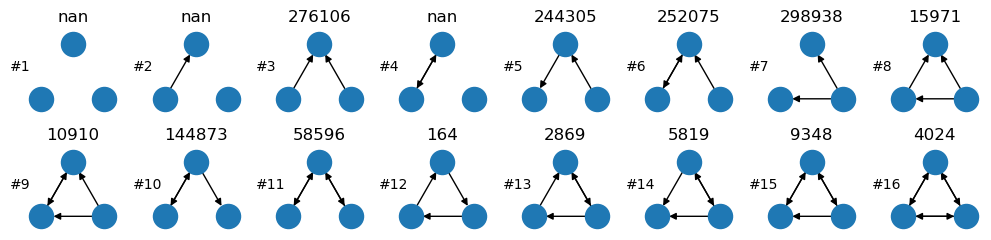

In [83]:
g = ig.Graph.from_networkx(G_lcc)

motifs_3 = g.motifs_randesu(size=3)

fig, ax = plt.subplots(2, 8, figsize=(10, 2.5))

pos = {
    0: (2, 2),
    1: (1, 0),
    2: (3, 0)
}

for idx, (i, j) in enumerate(itertools.product(range(2), range(8))):

    G = ig.Graph.to_networkx(ig.Graph.Isoclass(n=3, cls=idx, directed=True))
    nx.draw(G, pos=pos, ax=ax[i, j])#, with_labels=True)
    ax[i, j].set_xlim(0.5, 3.5)
    ax[i, j].set_ylim(-0.5, 2.5)
    ax[i, j].set_title(motifs_3[idx])
    ax[i, j].text(0, 1, f"#{idx+1}")

# plt.suptitle("Observed 3-motifs")
plt.tight_layout()
plt.savefig(f"../figures/observed_3_motifs_{name}.png")

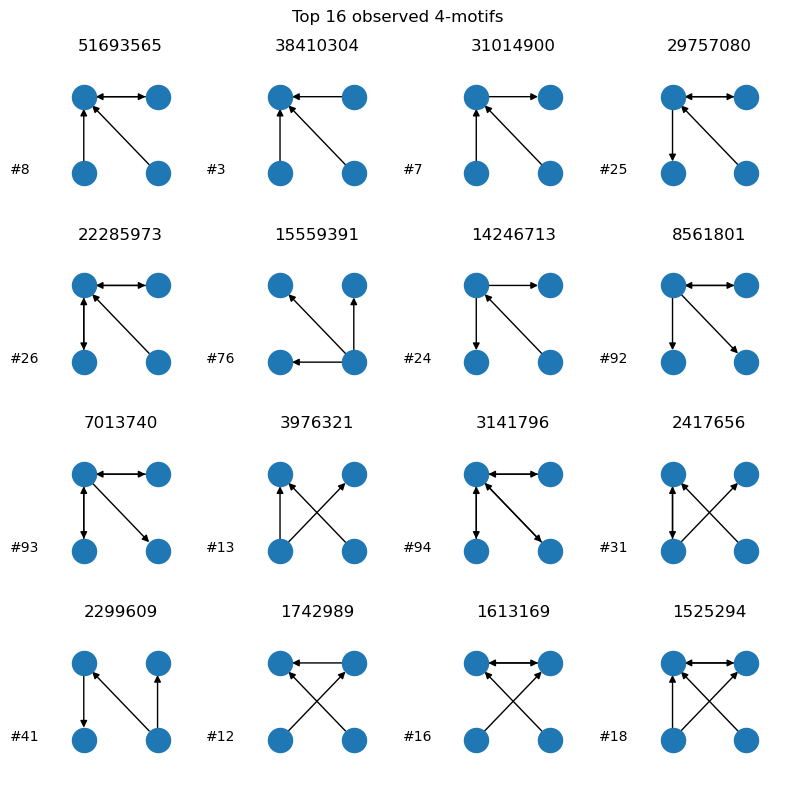

In [8]:
g = ig.Graph.from_networkx(G_lcc)

motifs_4 = g.motifs_randesu(size=4)

motifs_4 = np.nan_to_num(motifs_4, nan=-1).astype(int)

top_n = 16

top_n_idx = list(np.argsort(motifs_4)[-(top_n):])

top_n_values = list([motifs_4[i] for i in top_n_idx])


fig, ax = plt.subplots(4, 4, figsize=(8, 8))

pos = {
    0: (1, 2),
    1: (2, 2),
    2: (1, 1),
    3: (2, 1),
}

for idx, (i, j) in enumerate(itertools.product(range(4), range(4))):

    G = ig.Graph.to_networkx(ig.Graph.Isoclass(n=4, cls=top_n_idx[-idx-1], directed=True))
    nx.draw(G, pos=pos, ax=ax[i, j])#, with_labels=True)
    ax[i, j].set_xlim(0.5, 2.5)
    ax[i, j].set_ylim(0.5, 2.5)
    ax[i, j].set_title(top_n_values[-idx-1])
    ax[i, j].text(0, 1, f"#{top_n_idx[-idx-1]}")

# nx.draw(G, pos=pos, with_labels=True)
plt.suptitle("Top 16 observed 4-motifs")
plt.tight_layout()
plt.savefig(f"../figures/top_16_observed_4_motifs_{name}.png")

## Motifs in randomized networks

In [9]:
in_deg_seq = [G_lcc.in_degree[node] for node in G_lcc.nodes]
out_deg_seq = [G_lcc.out_degree[node] for node in G_lcc.nodes]

iters = 50

motifs_3_list = np.empty(shape=(iters, 16))

for i in range(iters):

    G_conf = nx.directed_configuration_model(in_deg_seq, out_deg_seq, seed=i)

    g_conf = ig.Graph.from_networkx(G_conf)

    motifs_3_conf = g_conf.motifs_randesu(size=3)

    motifs_3_list[i] = motifs_3_conf

motifs_3_list = np.nan_to_num(motifs_3_list, nan=0)


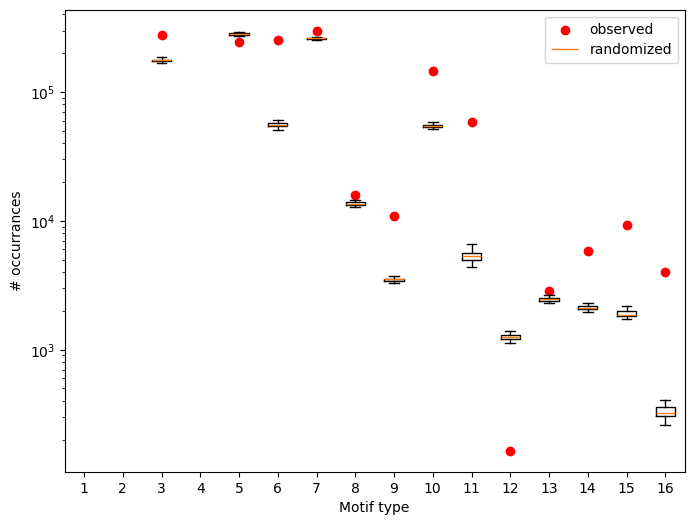

In [87]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))


ax.scatter(range(1, 17), motifs_3, marker="o", color="red", label="observed")
ax.boxplot(np.array(motifs_3_list), showfliers=False, label="randomized")
plt.yscale("log")

ax.set_xlabel("Motif type")
ax.set_ylabel("# occurrances")
# plt.title("Degree preserving randomization")
plt.legend()
plt.savefig(f"../figures/configuration_3_motifs_{name}.png")

In [70]:
mus = np.mean(motifs_3_list, axis=0)
sigmas = np.std(motifs_3_list, axis=0)

df_z = pd.DataFrame(
    index=range(16),
    columns=["min", "mean", "max", "std_dev", "observed", "z-score"]
)

for i in range(16):

    if sigmas[i] == 0:
        continue
    
    df_z.loc[i, "z-score"] = statistics.NormalDist(mu=mus[i], sigma=sigmas[i]).zscore(motifs_3[i])




df_z["min"] = np.min(motifs_3_list, axis=0).astype(int)
df_z["max"] = np.max(motifs_3_list, axis=0).astype(int)
df_z["mean"] = np.mean(motifs_3_list, axis=0).astype(int)
df_z["std_dev"] = np.std(motifs_3_list, axis=0).astype(int)

df_z["observed"] = np.nan_to_num(motifs_3, nan=0).astype(int)


df_z

,min,mean,max,std_dev,observed,z-score
0,0,0,0,0,0,NaN
1,0,0,0,0,0,NaN
2,168345,175776,187795,4325,276106,23.195083
3,0,0,0,0,0,NaN
4,269815,282450,297509,5587,244305,-6.82731
5,50266,56085,62689,2513,252075,77.961171
6,254319,260496,268127,3293,298938,11.672409
7,12786,13584,14457,392,15971,6.080476
8,3158,3498,3812,128,10910,57.866497
9,49852,54513,59382,1960,144873,46.088445


In [ ]:
df_z.to_latex("../data_out/latex/zscores2.tex", float_format="%0.2f", na_rep="--")

In [93]:
def degree_distribution(G, number_of_bins=15, log_binning=True, density=True, directed=False):
    """
    Given a degree sequence, return the y values (probability) and the
    x values (support) of a degree distribution that you're going to plot.
    
    Parameters
    ----------
    G (nx.Graph):
        the network whose degree distribution to calculate

    number_of_bins (int):
        length of output vectors
    
    log_binning (bool):
        if you are plotting on a log-log axis, then this is useful
    
    density (bool):
        whether to return counts or probability density (default: True)
        Note: probability densities integrate to 1 but do not sum to 1. 

    directed (bool or str):
        if False, this assumes the network is undirected. Otherwise, the
        function requires an 'in' or 'out' as input, which will create the 
        in- or out-degree distributions, respectively.
        
    Returns
    -------
    bins_out, probs (np.ndarray):
        probability density if density=True node counts if density=False; binned edges
    
    """

    # Step 0: Do we want the directed or undirected degree distribution?
    if directed:
        if directed=='in':
            k = list(dict(G.in_degree()).values()) # get the in degree of each node
        elif directed=='out':
            k = list(dict(G.out_degree()).values()) # get the out degree of each node
        else:
            out_error = "Help! if directed!=False, the input needs to be either 'in' or 'out'"
            print(out_error)
            # Question: Is this the correct way to raise an error message in Python?
            #           See "raise" function...
            return out_error
    else:
        k = list(dict(G.degree()).values()) # get the degree of each node


    # Step 1: We will first need to define the support of our distribution
    kmax = np.max(k)    # get the maximum degree
    kmin = 0            # let's assume kmin must be 0


    # Step 2: Then we'll need to construct bins
    if log_binning:
        # array of bin edges including rightmost and leftmost
        bins = np.logspace(0, np.log10(kmax+1), number_of_bins+1)
    else:
        bins = np.linspace(0, kmax+1, num=number_of_bins+1)


    # Step 3: Then we can compute the histogram using numpy
    probs, _ = np.histogram(k, bins, density=density)


    # Step 4: Return not the "bins" but the midpoint between adjacent bin
    #         values. This is a better way to plot the distribution.
    bins_out = bins[1:] - np.diff(bins)/2.0
    
    return bins_out, probs



def get_gamma(G: nx.Graph) -> float:
    """
    Gets the estimated gamma for a BA graph
    
    """

    degree = list(dict(G.degree()).values()) # Degree sequence

    # Initialize and fit the Hill estimator
    estimator = HillEstimator()
    estimator.fit(degree)

    # # # Get estimated values
    result = estimator.get_result()
    gamma = result.gamma_

    return gamma



In [94]:
gamma = np.mean([get_gamma(G_lang) for _ in range(100)]).astype(float)

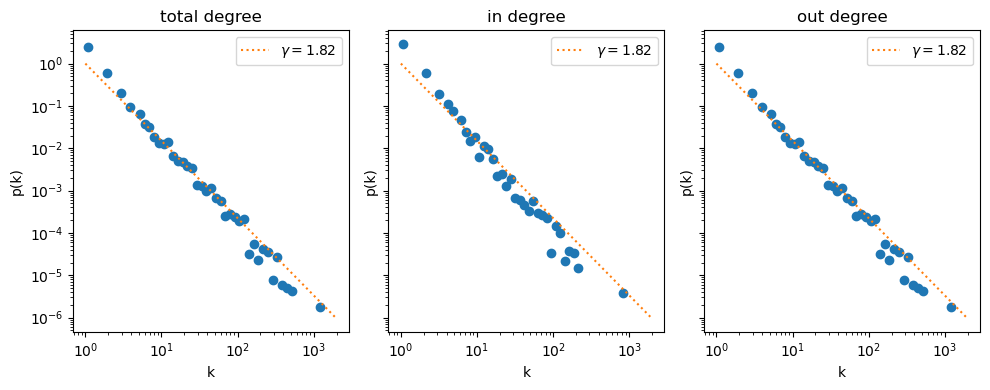

In [95]:

fig, ax = plt.subplots(1, 3, figsize=(10, 4), sharex=True,sharey=True)


x0, y0 = degree_distribution(G_lang, number_of_bins=50)#, weight="weight")

x00 = np.arange(1, 2*10**3, 10)
y00 = 1 / np.pow(x00, gamma) 

label = r"$\gamma = $" + f"{round(gamma, 2)}"

# print(x00, y00)
# print(x0, y0)
ax[0].loglog(x0, y0, "o")
ax[0].loglog(x00, y00, ":", label=label)
ax[0].set_title("total degree")
ax[0].set_xlabel("k")
ax[0].set_ylabel("p(k)")
ax[0].legend()


x1, y1 = degree_distribution(G_lang, directed="in", number_of_bins=50)#, weight="weight")

ax[1].loglog(x1, y1, "o")
ax[1].loglog(x00, y00, ":", label=label)
ax[1].set_title("in degree")
ax[1].set_xlabel("k")
ax[1].set_ylabel("p(k)")
ax[1].legend()


x2, y2 = degree_distribution(G_lang, directed="out", number_of_bins=50)#, weight="weight")

ax[2].loglog(x0, y0, "o")
ax[2].set_title("out degree")
ax[2].loglog(x00, y00, ":", label=label)
ax[2].set_xlabel("k")
ax[2].set_ylabel("p(k)")
ax[2].legend()


# fig.suptitle(f"Language network degree distribution")
fig.tight_layout()
plt.savefig("../figures/lang_deg_dist.png")